# Analítica Empresarial Integrada — Laboratorio D13
## Semana 13 · Gobierno de Datos y Cumplimiento Normativo
**TECSUP 2026-II · Docente: Pilar Rocío Sayán Mejía**

### Auditoría de un modelo
**Sesgo por subgrupos + explicabilidad con SHAP + checklist de gobierno/cumplimiento**

Caso reproducible: **UCI Adult (ID 2)**.

> Las variables sensibles se usan para **auditoría**, no para recomendar decisiones discriminatorias.  
> SHAP explica el comportamiento del modelo; **no demuestra causalidad**.

## Identificación

- **Estudiante** — Christopher Rojas Zuñiga
- **Uso de IA declarado** — ChatGPT como apoyo para desarrollar y verificar el laboratorio.

In [1]:
# En Colab, instala SHAP si el entorno todavía no lo tiene.
from importlib.util import find_spec

if find_spec("shap") is None:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])

In [2]:
import hashlib
from io import BytesIO
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from IPython.display import display
from scipy.special import expit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMILLA = 42
UMBRAL_BASE = 0.50
print("Versiones:", {"pandas": pd.__version__, "scikit-learn": sklearn.__version__, "SHAP": shap.__version__})

Versiones: {'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'SHAP': '0.54.1'}


# 1. Fuente, ficha y linaje

In [3]:
url_datos = "https://archive.ics.uci.edu/static/public/2/data.csv"
with urlopen(url_datos, timeout=60) as respuesta:
    contenido = respuesta.read()

adult = pd.read_csv(BytesIO(contenido))
X_raw = adult.drop(columns="income")
y_raw = adult["income"]

print(f"UCI Adult (ID 2) | {len(adult):,} registros | {X_raw.shape[1]} predictores originales")
print("SHA-256 del CSV:", hashlib.sha256(contenido).hexdigest())

UCI Adult (ID 2) | 48,842 registros | 14 predictores originales
SHA-256 del CSV: 26b38f8623766396e2ba0d1a235a283db8ed993cc32bf32fc8aab09708c3bdf2


In [4]:
X = X_raw.copy()
for columna in X.select_dtypes(include=["object", "string"]).columns:
    texto = X[columna].astype("string").str.strip()
    X[columna] = texto.mask(texto.eq("?")).to_numpy(dtype=object, na_value=np.nan)

etiquetas = y_raw.astype("string").str.strip().str.rstrip(".")
assert etiquetas.notna().all() and set(etiquetas.unique()) == {"<=50K", ">50K"}
y = etiquetas.eq(">50K").astype(int).rename("ingreso_mayor_50k")
assert X.index.is_unique and X.index.equals(y.index)

faltantes = X.isna().sum()
display(faltantes[faltantes.gt(0)].sort_values(ascending=False).to_frame("faltantes"))
display(y.value_counts(normalize=True).sort_index().mul(100).round(2).to_frame("porcentaje"))

,faltantes
occupation,2809
workclass,2799
native-country,857


,porcentaje
ingreso_mayor_50k,
0,76.07
1,23.93


### Ficha de gobierno

| Campo | Registro |
|---|---|
| Fuente | UCI Machine Learning Repository, *Adult*, ID 2. Extracción de la base censal estadounidense de 1994. Licencia CC BY 4.0. |
| Finalidad | Evaluar desempeño, diferencias entre grupos y explicaciones del modelo en un ejercicio académico. |
| Objetivo | `income` vale 1 si el ingreso anual supera US$ 50 000 y 0 si es igual o inferior. |
| Responsabilidad propuesta | El estudiante documenta la ejecución. La docente revisa las conclusiones del laboratorio. |
| Atributos de auditoría | `sex` y `race` se conservan en una tabla separada. La edad se usa como predictor y como dimensión de auditoría. |
| Calidad | Valido las etiquetas y cuento los faltantes. El entrenamiento aprende la mediana numérica y la moda categórica usadas para imputar. |
| Linaje | CSV oficial → limpieza → separación de atributos → partición → preprocesamiento → modelo → métricas, SHAP y checklist. |
| Alcance | Las métricas cuentan cada registro por igual. El análisis no estima tasas ponderadas para la población censal. |

### Pregunta 1
¿Qué información del origen y significado de los datos debería conocer un responsable antes de aprobar el uso del modelo?

**Respuesta**

Primero revisaría de dónde salió la muestra, a quiénes representa y para qué se recolectó. Aquí es una extracción de Estados Unidos de 1994 y el objetivo solo separa los ingresos por encima o por debajo de US$ 50 000. También revisaría el diccionario de datos, el peso censal `fnlwgt`, los faltantes, la licencia y el responsable de autorizar otro uso.

### Pregunta 2
¿Qué diferencia existe entre tener un archivo de datos y tener datos gobernados?

**Respuesta**

Con un archivo puedo abrir y consultar registros. Con datos gobernados también puedo saber quién responde por ellos, qué significa cada campo, cómo se transformó, quién tiene acceso y qué evidencia queda cuando cambia algo. Por ejemplo, en este laboratorio se registran el origen del CSV y las reglas para imputar faltantes.

# 2. Separación de variables sensibles para auditoría

In [5]:
sensibles = ["sex", "race"]
audit = X[sensibles].astype("string").fillna("Sin dato")
X_model = X.drop(columns=sensibles)
assert set(sensibles).isdisjoint(X_model.columns)
print(f"Predictores para entrenamiento: {X_model.shape[1]}")

Predictores para entrenamiento: 12


### Pregunta 3
¿Por qué excluir una variable sensible del entrenamiento no garantiza por sí solo ausencia de sesgo?

**Respuesta**

Aunque retire `sex`, hay categorías en `relationship` y `marital-status` muy asociadas al sexo. El modelo puede usar esas señales de forma indirecta. Además, las diferencias del conjunto histórico pueden pasar al entrenamiento, por eso reviso los errores con los atributos de auditoría separados.

# 3. Train/test y modelo base

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_model, y, test_size=0.25, stratify=y, random_state=SEMILLA
)
audit_test = audit.loc[X_test.index]
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.columns.difference(num_cols, sort=False).tolist()

preparacion = ColumnTransformer([
    ("num", Pipeline([
        ("mediana", SimpleImputer(strategy="median")),
        ("escalado", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("moda", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
], verbose_feature_names_out=False)
pipe = Pipeline([
    ("prep", preparacion),
    ("model", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEMILLA)),
])

pipe.fit(X_train, y_train)
proba = pd.Series(pipe.predict_proba(X_test)[:, 1], index=X_test.index, name="proba")
pred = proba.ge(UMBRAL_BASE).astype(int).rename("y_pred")
global_metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "f1": f1_score(y_test, pred),
}])
print(f"Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,} | Umbral: {UMBRAL_BASE:.2f}")
display(global_metrics.round(4))

Entrenamiento: 36,631 | Prueba: 12,211 | Umbral: 0.50


,accuracy,precision,recall,f1
0,0.8012,0.5566,0.8323,0.6671


# 4. Auditoría por subgrupos

**FNR** mide los casos positivos reales que el modelo omitió. **FPR** mide los negativos reales que clasificó como positivos. La tasa de predicciones positivas toma como base a todo el grupo. Las tasas se calculan para grupos con al menos 100 registros. El peso balanceado ayuda a que la clase minoritaria influya en el ajuste; los puntajes de probabilidad se reportan sin calibración adicional.

In [7]:
audit_result = audit_test.assign(y_true=y_test, y_pred=pred, proba=proba)
assert audit_result[["y_true", "y_pred", "proba"]].notna().all().all()

def group_metrics(datos, dimension, min_n=100):
    filas = []
    for grupo, muestra in datos.groupby(dimension, observed=True, dropna=False):
        if len(muestra) < min_n:
            continue
        tn, fp, fn, tp = confusion_matrix(muestra.y_true, muestra.y_pred, labels=[0, 1]).ravel()
        positivos = tp + fn
        negativos = tn + fp
        filas.append({
            "dimension": dimension, "group": str(grupo), "n": len(muestra),
            "positivos_reales": positivos, "negativos_reales": negativos,
            "falsos_positivos": fp, "falsos_negativos": fn,
            "positive_rate_pred": muestra.y_pred.mean(),
            "accuracy": (tp + tn) / len(muestra),
            "recall": tp / positivos if positivos else np.nan,
            "fpr": fp / negativos if negativos else np.nan,
            "fnr": fn / positivos if positivos else np.nan,
        })
    return pd.DataFrame(filas)

gm_sex = group_metrics(audit_result, "sex")
gm_race = group_metrics(audit_result, "race")
group_table = pd.concat([gm_sex, gm_race], ignore_index=True)
display(group_table.round(4))

for dimension in ["sex", "race"]:
    tamanos = audit_result[dimension].value_counts()
    print(f"Grupos de {dimension} con menos de 100 observaciones:", tamanos[tamanos.lt(100)].to_dict())

,dimension,group,n,positivos_reales,negativos_reales,falsos_positivos,falsos_negativos,positive_rate_pred,accuracy,recall,fpr,fnr
0,sex,Female,4057,453,3604,304,132,0.1541,0.8925,0.7086,0.0844,0.2914
1,sex,Male,8154,2469,5685,1633,358,0.4592,0.7558,0.8550,0.2872,0.1450
2,race,Amer-Indian-Eskimo,126,11,115,25,2,0.2698,0.7857,0.8182,0.2174,0.1818
3,race,Asian-Pac-Islander,369,96,273,64,19,0.3821,0.7751,0.8021,0.2344,0.1979
4,race,Black,1186,144,1042,108,38,0.1804,0.8769,0.7361,0.1036,0.2639
5,race,White,10442,2660,7782,1731,428,0.3795,0.7932,0.8391,0.2224,0.1609


Grupos de sex con menos de 100 observaciones: {}
Grupos de race con menos de 100 observaciones: {'Other': 88}


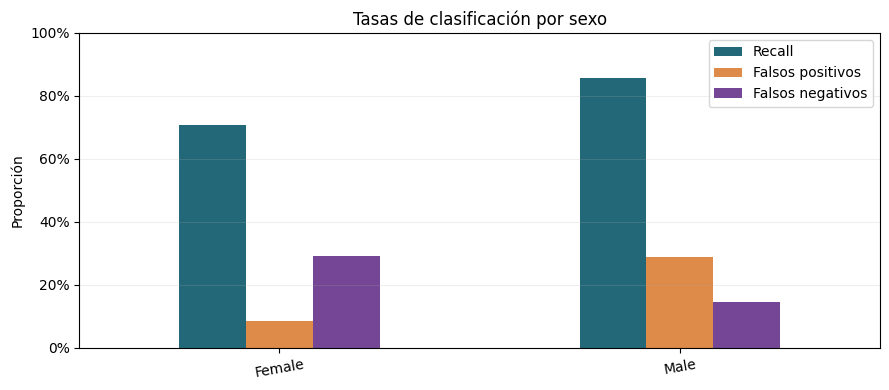

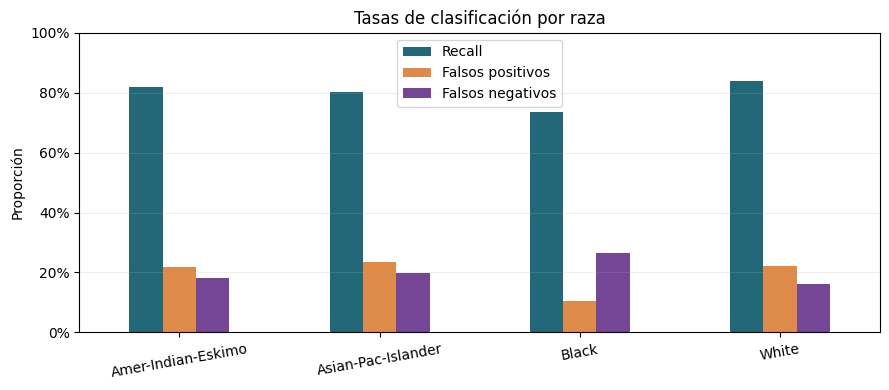

In [8]:
from matplotlib.ticker import PercentFormatter

for dimension, titulo in [("sex", "sexo"), ("race", "raza")]:
    tasas = group_table.query("dimension == @dimension").set_index("group")
    tasas = tasas[["recall", "fpr", "fnr"]].rename(columns={
        "recall": "Recall", "fpr": "Falsos positivos", "fnr": "Falsos negativos",
    })
    ax = tasas.plot.bar(figsize=(9, 4), color=["#236878", "#de8a48", "#744695"], rot=10)
    ax.set(title=f"Tasas de clasificación por {titulo}", xlabel="", ylabel="Proporción", ylim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()

### Pregunta 4
¿Qué métrica global podría ocultar una diferencia importante entre grupos?

**Respuesta**

Miraría con cuidado el **80,12 % de acierto global**. Las mujeres tienen más aciertos totales (89,25 % frente a 75,58 %), en una muestra donde 3 604 de 4 057 pertenecen a la clase negativa. Entre las personas que sí superan US$ 50 000, el modelo deja fuera al 29,14 % de las mujeres y al 14,50 % de los hombres.

### Pregunta 5
¿Qué brecha observada merece primero una revisión empresarial? Sustente con magnitud, tamaño de grupo y tipo de error.

**Respuesta**

Revisaría primero el **FNR por sexo**. En prueba hay 4 057 mujeres y 8 154 hombres. De quienes realmente superaban US$ 50 000, el modelo omitió a 132 de 453 mujeres (29,14 %) y a 358 de 2 469 hombres (14,50 %), una diferencia de 14,64 puntos porcentuales. También revisaría el costo de los falsos positivos, cuya tasa es mayor en hombres (28,72 % frente a 8,44 %).

# 5. Brechas cuantificadas

In [9]:
def gap_report(tabla, metrica):
    comparables = tabla.dropna(subset=[metrica])
    if len(comparables) < 2:
        return None
    mayor = comparables.loc[comparables[metrica].idxmax()]
    menor = comparables.loc[comparables[metrica].idxmin()]
    return {
        "metric": metrica, "max_group": mayor["group"], "min_group": menor["group"],
        "max_value": mayor[metrica], "min_value": menor[metrica],
        "brecha_pp": 100 * (mayor[metrica] - menor[metrica]),
    }

metricas = ["positive_rate_pred", "recall", "fpr", "fnr"]
filas_brecha = []
for dimension, tabla in group_table.groupby("dimension"):
    for metrica in metricas:
        reporte = gap_report(tabla, metrica)
        if reporte is not None:
            filas_brecha.append({"dimension": dimension, **reporte})
gap_df = pd.DataFrame(filas_brecha).sort_values("brecha_pp", ascending=False)
display(gap_df.round(4))

,dimension,metric,max_group,min_group,max_value,min_value,brecha_pp
4,sex,positive_rate_pred,Male,Female,0.4592,0.1541,30.5106
6,sex,fpr,Male,Female,0.2872,0.0844,20.2896
0,race,positive_rate_pred,Asian-Pac-Islander,Black,0.3821,0.1804,20.1675
5,sex,recall,Male,Female,0.8550,0.7086,14.6393
7,sex,fnr,Female,Male,0.2914,0.1450,14.6393
2,race,fpr,Asian-Pac-Islander,Black,0.2344,0.1036,13.0785
3,race,fnr,Black,White,0.2639,0.1609,10.2987
1,race,recall,White,Black,0.8391,0.7361,10.2987


# 6. Explicabilidad con SHAP

Uso 500 casos de prueba y una referencia de 100 registros de entrenamiento. Los aportes de la regresión logística se expresan en log-odds. Para interpretar el caso individual convierto a probabilidad la suma del valor base y los aportes.

,SHAP absoluto medio
marital-status_Married-civ-spouse,0.7455
capital-gain,0.7250
education-num,0.5364
marital-status_Never-married,0.4765
age,0.3060
hours-per-week,0.2865


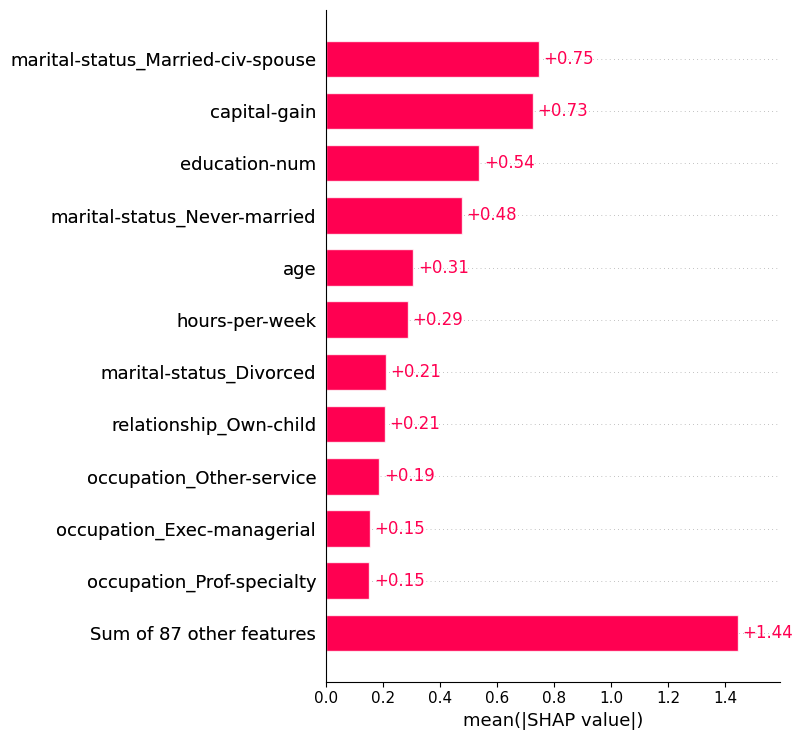

In [10]:
transformer = pipe.named_steps["prep"]
model = pipe.named_steps["model"]
feature_names = transformer.get_feature_names_out()
X_train_t = transformer.transform(X_train)
X_test_t = transformer.transform(X_test)

rng = np.random.default_rng(SEMILLA)
posiciones = rng.choice(len(X_test), size=min(500, len(X_test)), replace=False)
X_shap = X_test_t[posiciones]
fondo = shap.maskers.Independent(X_train_t, max_samples=100)
explainer = shap.LinearExplainer(model, fondo, feature_names=list(feature_names))
shap_values = explainer(X_shap)
imp_cols = pd.Series(np.abs(shap_values.values).mean(axis=0), index=feature_names)
display(imp_cols.nlargest(6).round(4).to_frame("SHAP absoluto medio"))
shap.plots.bar(shap_values, max_display=12, show=False)
plt.tight_layout()
plt.show()

Probabilidad base: 23.05% | Predicción del caso: 19.93% | Clase real: 0


,aporte en log-odds
age,0.7256
occupation_Exec-managerial,0.4897
marital-status_Never-married,0.3230
education-num,-1.1682
marital-status_Married-civ-spouse,-0.6111
marital-status_Divorced,-0.5627


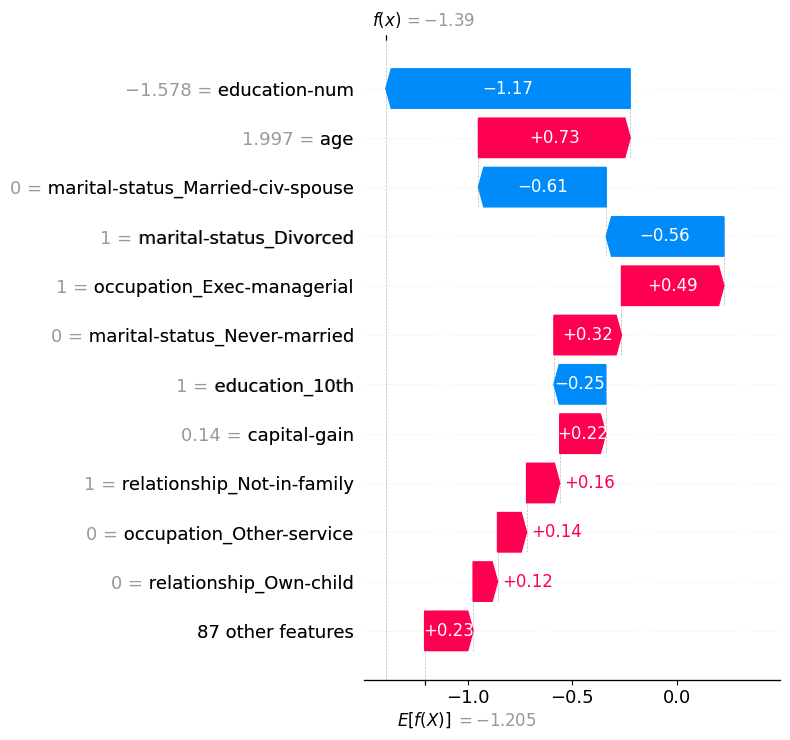

In [11]:
caso = 0
explicacion = shap_values[caso]
fila = X_test.index[posiciones[caso]]
prob_base = expit(float(explicacion.base_values))
prob_caso = expit(float(explicacion.base_values) + explicacion.values.sum())
assert np.isclose(prob_caso, proba.loc[fila])
print(f"Probabilidad base: {prob_base:.2%} | Predicción del caso: {prob_caso:.2%} | Clase real: {y_test.loc[fila]}")
aportes = pd.Series(explicacion.values, index=feature_names)
display(pd.concat([aportes.nlargest(3), aportes.nsmallest(3)]).round(4).to_frame("aporte en log-odds"))
shap.plots.waterfall(explicacion, max_display=12, show=False)
plt.tight_layout()
plt.show()

### Pregunta 6
¿Cuáles variables tienen mayor influencia global en las predicciones?

**Respuesta**

Al ordenar las columnas por aporte absoluto medio, aparecen primero `marital-status_Married-civ-spouse` (0,7455), `capital-gain` (0,7250) y `education-num` (0,5364). Estos valores resumen cuánto pesan en las predicciones de los 500 casos explicados, en la escala de log-odds.

### Pregunta 7
Elija una predicción y explique qué variables aumentaron o redujeron la probabilidad estimada. No use lenguaje causal.

**Respuesta**

En el caso 0, el modelo estimó **19,93 %** frente al valor base de **23,05 %**. La edad (+0,73) y la categoría de ocupación ejecutiva (+0,49) empujaron el puntaje hacia arriba. El nivel educativo (−1,17) y la ausencia de la categoría `Married-civ-spouse` (−0,61) lo empujaron hacia abajo. Los aportes están expresados en log-odds.

# 7. Checklist académico de gobierno y cumplimiento

In [12]:
checklist = pd.DataFrame([
    ("Finalidad", "¿Se definió el uso del modelo?", "Parcial", "Se documentó el uso académico. Falta aprobación formal para otro uso."),
    ("Minimización", "¿Se justifica cada predictor?", "Parcial", "Se separaron sex y race. Falta justificar los atributos asociados con sexo."),
    ("Calidad", "¿Se midió la calidad de la fuente?", "Parcial", "Se validaron etiquetas y faltantes. Faltan criterios de aceptación."),
    ("Linaje", "¿Se puede reproducir el recorrido del dato?", "Parcial", "Se conservan URL, huella del CSV, versiones, semilla y pipeline."),
    ("Acceso", "¿Están definidos los permisos?", "No evidenciado", "No se presentó matriz de permisos ni registro de accesos."),
    ("Transparencia", "¿Se pueden explicar los resultados y límites?", "Parcial", "Hay gráficos SHAP e informe. Falta documentación para usuarios de un uso operativo."),
    ("Auditoría de subgrupos", "¿Se compararon tasas y errores?", "Cumple", "Se calcularon denominadores y matrices de confusión por sexo y raza."),
    ("Supervisión humana", "¿Hay alguien autorizado para intervenir?", "No evidenciado", "No hay designación ni procedimiento aprobado."),
], columns=["control", "pregunta", "estado_inicial", "evidencia"])
display(checklist)

,control,pregunta,estado_inicial,evidencia
0,Finalidad,¿Se definió el uso del modelo?,Parcial,Se documentó el uso académico. Falta aprobació...
1,Minimización,¿Se justifica cada predictor?,Parcial,Se separaron sex y race. Falta justificar los ...
2,Calidad,¿Se midió la calidad de la fuente?,Parcial,Se validaron etiquetas y faltantes. Faltan cri...
3,Linaje,¿Se puede reproducir el recorrido del dato?,Parcial,"Se conservan URL, huella del CSV, versiones, s..."
4,Acceso,¿Están definidos los permisos?,No evidenciado,No se presentó matriz de permisos ni registro ...
5,Transparencia,¿Se pueden explicar los resultados y límites?,Parcial,Hay gráficos SHAP e informe. Falta documentaci...
6,Auditoría de subgrupos,¿Se compararon tasas y errores?,Cumple,Se calcularon denominadores y matrices de conf...
7,Supervisión humana,¿Hay alguien autorizado para intervenir?,No evidenciado,No hay designación ni procedimiento aprobado.


Los estados del checklist son **Cumple**, **Parcial**, **No evidenciado** y **No aplica**.
La revisión se limita a la evidencia disponible en el laboratorio.

### Pregunta 8
¿Qué control no puede demostrarse solo con código y necesita evidencia organizacional adicional?

**Respuesta**

La supervisión humana requiere una designación formal y un procedimiento que indique quién puede detener o corregir una decisión. Para demostrar el control de acceso también conservaría la matriz de roles aprobada, el registro de accesos y evidencia de revisión periódica.

# 8. Registro de hallazgos y plan de acción

In [13]:
sexo = gm_sex.set_index("group")
raza = gm_race.set_index("group")
mujeres, hombres = sexo.loc["Female"], sexo.loc["Male"]

def tasa(valor):
    return format(valor, ".2%").replace(".", ",")

hallazgos = pd.DataFrame([
    ("Omisiones desiguales por sexo", "Alta",
     f"FNR mujeres {tasa(mujeres.fnr)} y hombres {tasa(hombres.fnr)}.",
     "Probar cambios en un conjunto de validación y reauditar por sexo.",
     "Responsable del modelo y negocio", "Abierto"),
    ("Predictores con señales indirectas del sexo", "Alta",
     "Ejercicio 1: Husband y Wife superan el 85 % para un solo sexo.",
     "Comparar el modelo con y sin estos predictores, midiendo acierto y equidad.",
     "Equipo de datos", "Abierto"),
    ("Diferencia de omisiones por raza", "Media",
     f"FNR Black {tasa(raza.loc['Black','fnr'])} y White {tasa(raza.loc['White','fnr'])}.",
     "Revisar denominadores e incertidumbre y ampliar la evidencia donde la muestra sea pequeña.",
     "Equipo de datos", "Abierto"),
    ("Controles organizacionales pendientes", "Alta",
     "El checklist no acredita acceso ni supervisión humana.",
     "Aprobar roles y designar a quien pueda revisar o detener decisiones.",
     "Gobierno de datos", "Abierto"),
], columns=["hallazgo", "severidad", "evidencia", "accion", "responsable", "estado"])
display(hallazgos)

,hallazgo,severidad,evidencia,accion,responsable,estado
0,Omisiones desiguales por sexo,Alta,"FNR mujeres 29,14% y hombres 14,50%.",Probar cambios en un conjunto de validación y ...,Responsable del modelo y negocio,Abierto
1,Predictores con señales indirectas del sexo,Alta,Ejercicio 1: Husband y Wife superan el 85 % pa...,Comparar el modelo con y sin estos predictores...,Equipo de datos,Abierto
2,Diferencia de omisiones por raza,Media,"FNR Black 26,39% y White 16,09%.",Revisar denominadores e incertidumbre y amplia...,Equipo de datos,Abierto
3,Controles organizacionales pendientes,Alta,El checklist no acredita acceso ni supervisión...,Aprobar roles y designar a quien pueda revisar...,Gobierno de datos,Abierto


### Pregunta 9
¿Qué hallazgo impediría desplegar el modelo hasta ser resuelto?

**Respuesta**

Detendría el despliegue para decisiones sobre personas por la brecha de falsos negativos por sexo sin mitigar. Antes de volver a evaluarlo, probaría el modelo con y sin los proxies y pediría una revisión de los errores por grupo con datos del uso previsto y supervisión humana designada.

### Pregunta 10
¿Qué evidencia conservaría para demostrar que el modelo fue auditado y revisado antes de su uso?

**Respuesta**

Guardaría la huella del CSV, el notebook ejecutado con versiones y semilla, y las tablas de métricas con sus denominadores. También archivaría los gráficos SHAP, las acciones con responsable y fecha, y el acta que documente la revisión y la decisión de aprobación.

# 9. Informe ejecutivo de auditoría

Resultados de la muestra de prueba y decisión sobre el uso operativo.

**A. Describa el desempeño global del modelo y dos métricas por subgrupo que matizan ese resultado.**

**Respuesta**

En 12 211 registros de prueba, el modelo acertó el 80,12 %. Su precisión fue 55,66 %, su recall 83,23 % y su F1 66,71 %. Por sexo, el recall fue 70,86 % en mujeres y 85,50 % en hombres. El FPR fue 8,44 % y 28,72 %, respectivamente.

**B. Identifique la principal brecha, indique el tamaño de los grupos involucrados y el tipo de error.**

**Respuesta**

La tasa de predicciones positivas difirió en 30,51 puntos por sexo. La prioridad es la omisión de casos que sí superaban US$ 50 000. El FNR fue 29,14 % en mujeres (n = 4 057 en total) y 14,50 % en hombres (n = 8 154).

**C. Presente una explicación SHAP global y una local, sin lenguaje causal.**

**Respuesta**

El estado civil concentra 28,94 % de la importancia SHAP agregada. En el caso 0, la edad elevó el puntaje y el nivel educativo lo redujo. La estimación final fue 19,93 %.

**D. Señale dos controles de gobierno revisados y una evidencia de cumplimiento faltante.**

**Respuesta**

Se verificó la auditoría por subgrupos y quedó documentado el linaje técnico. Falta la designación formal de la persona que puede revisar o detener decisiones.

**E. Indique una limitación y su recomendación: aprobar, aprobar con condiciones o no aprobar todavía.**

**Respuesta**

Los datos corresponden a un censo estadounidense de 1994. Mi recomendación es **no aprobar todavía** el uso operativo y volver a evaluar desempeño y brechas con datos de la población objetivo.

# 10. Reto de aplicación y retroalimentación

Cada respuesta escrita se mantiene dentro de cuatro líneas de contenido en el notebook.

In [14]:
# Objetos de trabajo para la sección de retos.
print("Variables del modelo:", X_model.shape)
print("Auditoría de prueba:", audit_result.shape)
print("Valores SHAP:", shap_values.values.shape)

Variables del modelo: (48842, 12)
Auditoría de prueba: (12211, 5)
Valores SHAP: (500, 98)


## Ejercicio 1 — Detección de variables proxy del sexo

- Construir una tabla cruzada entre relationship y el sexo de la tabla de auditoría, normalizada por fila.
- Construir la misma tabla para marital-status.
- Identificar las categorías en que un solo sexo supera el 85 % de los casos.

In [15]:
tablas_proxy = {}
for variable in ["relationship", "marital-status"]:
    conteo = pd.crosstab(X_model[variable].fillna("Sin dato"), audit["sex"])
    proporcion = conteo.div(conteo.sum(axis=1), axis=0)
    tabla = proporcion.assign(n=conteo.sum(axis=1), supera_85=proporcion.max(axis=1).gt(0.85))
    tablas_proxy[variable] = tabla
    print(f"Distribución del sexo dentro de cada categoría de {variable}")
    display(tabla.round(4))
    print("Categorías sobre el 85 %:", tabla.index[tabla["supera_85"]].tolist())

Distribución del sexo dentro de cada categoría de relationship


sex,Female,Male,n,supera_85
relationship,,,,
Husband,0.0001,0.9999,19716,True
Not-in-family,0.4665,0.5335,12583,False
Other-relative,0.4575,0.5425,1506,False
Own-child,0.4453,0.5547,7581,False
Unmarried,0.7664,0.2336,5125,False
Wife,0.9987,0.0013,2331,True


Categorías sobre el 85 %: ['Husband', 'Wife']
Distribución del sexo dentro de cada categoría de marital-status


sex,Female,Male,n,supera_85
marital-status,,,,
Divorced,0.6032,0.3968,6633,False
Married-AF-spouse,0.6757,0.3243,37,False
Married-civ-spouse,0.1108,0.8892,22379,True
Married-spouse-absent,0.4841,0.5159,628,False
Never-married,0.4479,0.5521,16117,False
Separated,0.6085,0.3915,1530,False
Widowed,0.8123,0.1877,1518,False


Categorías sobre el 85 %: ['Married-civ-spouse']


**Pregunta 11.** ¿Qué variable funciona como proxy más fuerte del sexo y qué implica para la decisión de excluir sex del modelo?

**Respuesta**

`relationship` es la señal más fuerte de las dos. En `Husband` el 99,99 % son hombres y en `Wife` el 99,87 % son mujeres. En estado civil, `Married-civ-spouse` llega a 88,92 % de hombres. Por eso, retirar `sex` deja señales indirectas; evaluaría qué cambia al retirar también esos predictores.

## Ejercicio 2 — Efecto del umbral de decisión sobre las brechas

- Recalcular las predicciones con umbrales de 0,30, 0,50 y 0,70.
- Obtener, para cada umbral, el FNR y el FPR de mujeres y de hombres con la función group_metrics.
- Construir las columnas brecha_fnr y brecha_fpr y presentar los resultados en una tabla.

In [16]:
resultados = []
for umbral in [0.30, UMBRAL_BASE, 0.70]:
    pred_umbral = audit_result["proba"].ge(umbral).astype(int)
    por_sexo = group_metrics(audit_result.assign(y_pred=pred_umbral), "sex").set_index("group")
    mujeres, hombres = por_sexo.loc["Female"], por_sexo.loc["Male"]
    resultados.append({
        "umbral": umbral, "fnr_mujeres": mujeres.fnr, "fnr_hombres": hombres.fnr,
        "fpr_mujeres": mujeres.fpr, "fpr_hombres": hombres.fpr,
        "brecha_fnr": abs(mujeres.fnr - hombres.fnr),
        "brecha_fpr": abs(mujeres.fpr - hombres.fpr),
    })
umbrales = pd.DataFrame(resultados)
display(umbrales.round(4))

,umbral,fnr_mujeres,fnr_hombres,fpr_mujeres,fpr_hombres,brecha_fnr,brecha_fpr
0,0.3,0.1545,0.0502,0.1615,0.4355,0.1043,0.2740
1,0.5,0.2914,0.1450,0.0844,0.2872,0.1464,0.2029
2,0.7,0.4371,0.3196,0.0366,0.1321,0.1175,0.0955


**Pregunta 12.** ¿Existe un umbral que elimine a la vez las brechas de FNR y de FPR? ¿Quién debería decidir el umbral final?

**Respuesta**

Entre 0,30, 0,50 y 0,70, ningún umbral elimina ambas brechas. Al subir a 0,70, la brecha de FPR baja a 9,55 puntos, pero el FNR llega a 43,71 % en mujeres y 31,96 % en hombres. Gobierno de datos, negocio y cumplimiento deben decidir con los costos de cada error y una muestra de validación.

## Ejercicio 3 — Nueva dimensión de auditoría: grupos de edad

- Crear la columna grupo_edad en audit_result con los tramos 17-29, 30-49 y 50+.
- Aplicar group_metrics a la nueva dimensión.
- Calcular con gap_report la brecha de FNR y la de tasa positiva predicha.

In [17]:
audit_result["grupo_edad"] = pd.cut(
    X_test["age"], bins=[16, 29, 49, np.inf], labels=["17-29", "30-49", "50+"]
)
assert audit_result["grupo_edad"].notna().all()
gm_edad = group_metrics(audit_result, "grupo_edad")
brechas_edad = pd.DataFrame([gap_report(gm_edad, metrica) for metrica in ["fnr", "positive_rate_pred"]])
display(gm_edad.round(4))
display(brechas_edad.round(4))

,dimension,group,n,positivos_reales,negativos_reales,falsos_positivos,falsos_negativos,positive_rate_pred,accuracy,recall,fpr,fnr
0,grupo_edad,17-29,3663,178,3485,230,51,0.0975,0.9233,0.7135,0.0660,0.2865
1,grupo_edad,30-49,5868,1857,4011,1038,322,0.4385,0.7682,0.8266,0.2588,0.1734
2,grupo_edad,50+,2680,887,1793,669,117,0.5369,0.7067,0.8681,0.3731,0.1319


,metric,max_group,min_group,max_value,min_value,brecha_pp
0,fnr,17-29,50+,0.2865,0.1319,15.4612
1,positive_rate_pred,50+,17-29,0.5369,0.0975,43.9479


**Pregunta 13.** ¿Qué grupo de edad resulta más afectado por los falsos negativos y qué tamaño tiene?

**Respuesta**

El tramo **17 a 29 años** tiene el mayor FNR, **28,65 %**. Son 3 663 personas y 178 realmente superan US$ 50 000. En el grupo de 50 años a más, el FNR es 13,19 %. La diferencia es de 15,46 puntos porcentuales.

## Ejercicio 4 — Importancia SHAP agregada por variable original

- Calcular el promedio del valor SHAP absoluto de cada columna transformada.
- Asignar cada columna a su variable original.
- Sumar la importancia por variable original y ordenarla de mayor a menor.

,importancia_shap,porcentaje
marital-status,1.570,28.941
occupation,0.816,15.042
capital-gain,0.725,13.362
education-num,0.536,9.885
relationship,0.465,8.565
age,0.306,5.639
hours-per-week,0.287,5.281
education,0.234,4.320
workclass,0.214,3.946
native-country,0.188,3.465


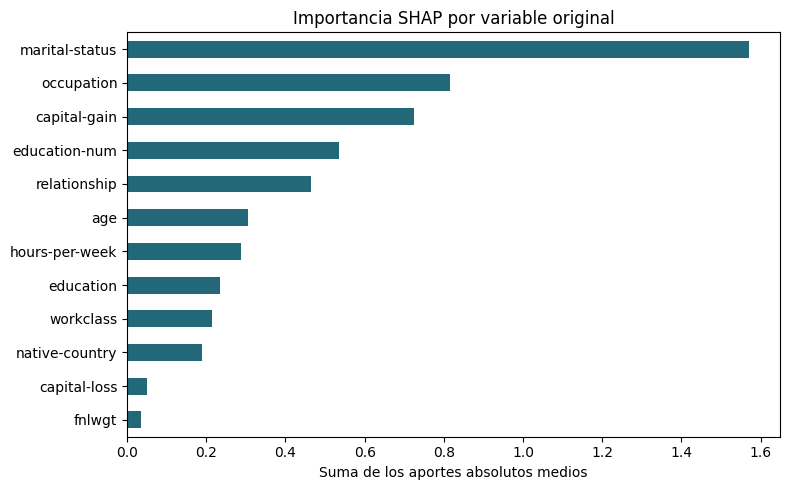

In [18]:
codificador = transformer.named_transformers_["cat"].named_steps["onehot"]
origenes = num_cols + [
    variable
    for variable, categorias in zip(cat_cols, codificador.categories_)
    for _ in categorias
]
assert len(origenes) == len(feature_names)
imp_var = imp_cols.groupby(origenes).sum().sort_values(ascending=False).to_frame("importancia_shap")
imp_var["porcentaje"] = 100 * imp_var["importancia_shap"] / imp_var["importancia_shap"].sum()
display(imp_var.round(3))

ax = imp_var["importancia_shap"].sort_values().plot.barh(figsize=(8, 5), color="#236878")
ax.set(title="Importancia SHAP por variable original", xlabel="Suma de los aportes absolutos medios")
plt.tight_layout()
plt.show()

**Pregunta 14.** ¿Qué variable original concentra mayor importancia y qué relación tiene con el hallazgo del Ejercicio 1?

**Respuesta**

`marital-status` lidera con **28,94 %** de la importancia agregada; `relationship` aporta **8,57 %**. La suma redondeada de ambas es **37,51 %**. El ejercicio 1 mostró categorías muy asociadas al sexo en estas dos variables, así que conviene medir qué ocurre si se retiran.

## Ejercicio 5 — Checklist con base normativa y estado final

- Agregar la columna base_normativa (Ley 29733 y DS 016-2024-JUS, Ley 31814 y DS 115-2025-PCM o DAMA-DMBOK).
- Agregar la columna estado_final con los estados Cumple, Parcial, No evidenciado o No aplica.
- Contar los controles por estado final.

In [19]:
datos_personales = "Ley 29733 y D.S. 016-2024-JUS"
inteligencia_artificial = "Ley 31814 y D.S. 115-2025-PCM"
dama = "DAMA-DMBOK"

controles_finales = [
    ("Finalidad", datos_personales, "Parcial", "Aprobar finalidad y alcance si cambia el uso."),
    ("Minimización", datos_personales, "Parcial", "Justificar predictores y evaluar proxies en validación."),
    ("Calidad", dama, "Parcial", "Acordar umbrales de aceptación y responsable de calidad."),
    ("Linaje", dama, "Parcial", "Registrar el origen y los cambios en un catálogo versionado."),
    ("Acceso", dama, "No evidenciado", "Aprobar matriz de roles y conservar registros de acceso."),
    ("Transparencia", inteligencia_artificial, "Parcial", "Documentar limitaciones y comunicar el uso del modelo."),
    ("Auditoría de subgrupos", inteligencia_artificial, "Cumple", "Se compararon resultados por sexo, raza y edad."),
    ("Supervisión humana", inteligencia_artificial, "No evidenciado", "Designar a quien pueda detener o corregir decisiones."),
]
matriz_final = pd.DataFrame(controles_finales, columns=[
    "control", "base_normativa", "estado_final", "evidencia_o_accion",
])
checklist_final = checklist.merge(matriz_final, on="control", validate="one_to_one")
orden = ["Cumple", "Parcial", "No evidenciado", "No aplica"]
conteo_estados = checklist_final["estado_final"].value_counts().reindex(orden, fill_value=0)
display(checklist_final[["control", "base_normativa", "estado_final", "evidencia_o_accion"]])
display(conteo_estados.to_frame("controles"))

,control,base_normativa,estado_final,evidencia_o_accion
0,Finalidad,Ley 29733 y D.S. 016-2024-JUS,Parcial,Aprobar finalidad y alcance si cambia el uso.
1,Minimización,Ley 29733 y D.S. 016-2024-JUS,Parcial,Justificar predictores y evaluar proxies en va...
2,Calidad,DAMA-DMBOK,Parcial,Acordar umbrales de aceptación y responsable d...
3,Linaje,DAMA-DMBOK,Parcial,Registrar el origen y los cambios en un catálo...
4,Acceso,DAMA-DMBOK,No evidenciado,Aprobar matriz de roles y conservar registros ...
5,Transparencia,Ley 31814 y D.S. 115-2025-PCM,Parcial,Documentar limitaciones y comunicar el uso del...
6,Auditoría de subgrupos,Ley 31814 y D.S. 115-2025-PCM,Cumple,"Se compararon resultados por sexo, raza y edad."
7,Supervisión humana,Ley 31814 y D.S. 115-2025-PCM,No evidenciado,Designar a quien pueda detener o corregir deci...


,controles
estado_final,
Cumple,1
Parcial,5
No evidenciado,2
No aplica,0


**Pregunta 15.** ¿Cuántos controles quedan como No evidenciado y qué acción concreta propone para cada uno?

**Respuesta**

Quedan **2 controles sin evidencia**. Para acceso, prepararía una matriz con quién puede leer, modificar o exportar datos y la contrastaría con los registros de actividad. Para supervisión, nombraría a un responsable con autoridad para detener decisiones y dejaría por escrito cómo se escala cada caso.

# 11. Retroalimentación final — DAMA-DMBOK y marco normativo

**Pregunta 16.** A partir de lo realizado, identifique qué áreas de conocimiento de DAMA-DMBOK se evidencian directamente en este laboratorio. Justifique en un máximo de tres líneas.

**Respuesta**

**Gobierno** en la ficha y la asignación propuesta de responsables, **calidad** en la limpieza e imputación, y **metadatos** en la huella y el linaje. La separación de atributos aporta una medida de privacidad y la comparación de errores por grupos pone en práctica la ética de datos.

**Pregunta 17.** Ley 29733 y DS 016-2024-JUS. ¿Qué datos del caso tendrían la condición de datos sensibles y qué obligación deriva de ello?

**Respuesta**

Si los registros permitieran identificar a personas, `race` y `income` incluirían datos sensibles por referirse al origen racial o étnico y a los ingresos económicos. Corresponde definir finalidad y aplicar medidas de seguridad. Cuando el consentimiento sea la base, debe ser previo, informado, expreso, inequívoco y constar por escrito, según el art. 13 de la Ley 29733. La ley contempla supuestos de excepción.

**Pregunta 18.** Ley 31814 y DS 115-2025-PCM. ¿En qué nivel de riesgo ubicaría el uso del modelo y qué control sería indispensable antes de desplegarlo?

**Respuesta**

Si se usara para determinar una evaluación crediticia real, lo clasificaría como **riesgo alto** según el art. 24.1 del D.S. 115-2025-PCM. Antes de ese uso exigiría supervisión humana con personal capacitado para detener, corregir o invalidar decisiones, además de un registro de datos y lógica del sistema (art. 31).

# 12. Conclusiones

1. El modelo obtuvo 80,12 % de acierto. La auditoría mostró que, entre quienes realmente superaban el umbral de ingresos, la tasa de omisión fue 14,64 puntos mayor en mujeres.
2. Detecté categorías asociadas al sexo en `relationship` y `marital-status`. El estado civil, además, lideró la importancia agrupada según SHAP. Los tres umbrales probados redistribuyeron los errores entre grupos.
3. La auditoría académica se completó. El checklist deja un control en Cumple, cinco en Parcial y dos sin evidencia. Antes de un uso operativo, corresponde evaluar los proxies con datos representativos y documentar acceso y supervisión humana.

# 13. Checklist de entrega

- [x] Identificación y declaración de uso de IA.
- [x] Fuente UCI Adult ID 2, ficha, linaje y control de calidad.
- [x] Separación de atributos y entrenamiento reproducible.
- [x] Métricas globales, auditoría por subgrupos y brechas.
- [x] Explicaciones SHAP global, local y agregada.
- [x] Checklist, registro de hallazgos e informe ejecutivo.
- [x] Cinco retos, retroalimentación y conclusiones.
- [ ] Enlaces propios de Colab y GitHub.

# Referencias

- Becker, B. y Kohavi, R. (1996). [Adult](https://doi.org/10.24432/C5XW20). UCI Machine Learning Repository. CC BY 4.0.
- Congreso de la República del Perú. [Ley N.º 29733, Ley de Protección de Datos Personales](https://www.congreso.gob.pe/Docs/DGP/DIDP/files/ley_29733.pdf), arts. 2 y 13.
- Ministerio de Justicia y Derechos Humanos. [D.S. N.º 016-2024-JUS](https://www.gob.pe/institucion/anpd/normas-legales/6554453-n-016-2024-jus), Reglamento de la Ley N.º 29733.
- Presidencia del Consejo de Ministros. [D.S. N.º 115-2025-PCM](https://www.gob.pe/institucion/pcm/normas-legales/7133522-115-2025-), Reglamento de la Ley N.º 31814, arts. 24 y 31.
- DAMA International. *DAMA-DMBOK*, segunda edición revisada.